# 06 · End to end: from spectra to an orbit

**What you'll learn**

- how to simulate a season of HARPS-like observations of a star with a companion
- how the pieces of notebooks 02 and 05 chain together: spectra → RVs → periodogram
- how to fit the orbit and check the period and amplitude against the truth
- why nightly sampling creates 1-day aliases

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

from sparta import Observations
from sparta.instruments import Simulation
from sparta.instruments.simulated import component_templates

plt.rcParams.update({
    "figure.figsize": (8, 3.2), "figure.dpi": 100, "figure.constrained_layout.use": True,
    "font.size": 11, "axes.titlesize": 11, "legend.fontsize": 9, "legend.frameon": False,
})

## 1. The observing schedule

A typical ground-based season: 40 clear nights scattered over 120, one spectrum per night, taken
near local midnight (within about ±1.5 hours).

In [2]:
rng = np.random.default_rng(5)
nights = np.sort(rng.choice(120, size=40, replace=False))
times = nights + 0.5 + rng.normal(0, 0.06, nights.size)          # days
print(f"{times.size} epochs over {np.ptp(times):.0f} days")

40 epochs over 116 days


## 2. The star and its orbit

A Sun-like star (PHOENIX 5500 K) with an unseen companion on a circular 3.17-day orbit,
semi-amplitude 12 m/s, systemic velocity −10 km/s: a single-lined (SB1) orbit. The spectra are
simulated as the HARPS archive would deliver them (`as_product=True`: rebinned onto its 0.01 Å
grid), at signal-to-noise 50 per pixel.

In [3]:
P_true, K_true, gamma_true = 3.17, 0.012, -10.0                  # days, km/s, km/s
rv_true = gamma_true + K_true * np.sin(2 * np.pi * times / P_true + 0.7)

sim = Simulation(like="HARPS", components=[dict(teff=5500, logg=4.5, vsini=2.0)],
                 times=times, rv_kms=rv_true, snr=50, seed=5, as_product=True)
obs = Observations(survey="SIMULATED", simulation=sim)
print(f"{obs.sample_size} spectra, {obs.spec_list[0].wv[0][0]:.1f}-{obs.spec_list[0].wv[0][-1]:.1f} Å")

40 spectra, 4990.0-5090.0 Å


## 3. Radial velocities

UNICOR against the matched template (notebook 02). The RVs and their errors go into
`obs.vels` / `obs.evels`, and into the time series that the periodograms read.

In [4]:
obs.calc_rv_against_template(component_templates(sim)[0], dv=0.1, vel_bound=30)
t = np.asarray(obs.time_list)
print(f"median RV uncertainty: {np.median(obs.evels) * 1e3:.1f} m/s;  "
      f"rms about the truth: {np.std(obs.vels - rv_true) * 1e3:.1f} m/s;  K = {K_true * 1e3:.0f} m/s")

100%|██████████| 40/40 [00:00<00:00, 138.79it/s]

median RV uncertainty: 3.5 m/s;  rms about the truth: 2.8 m/s;  K = 12 m/s


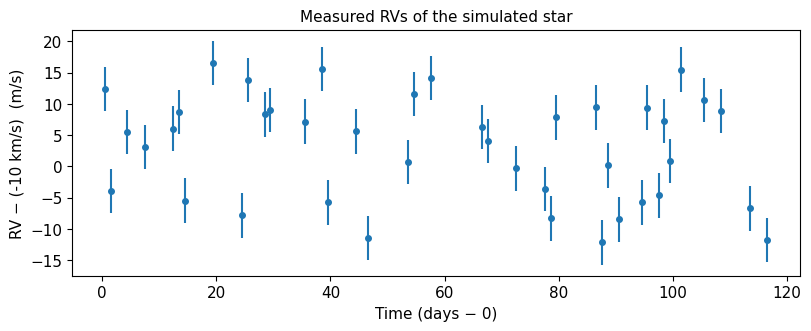

In [5]:
fig, ax = plt.subplots()
ax.errorbar(t, (obs.vels - gamma_true) * 1e3, obs.evels * 1e3, fmt="o", color="tab:blue", ms=4)
ax.set_xlabel(f"Time (days − {obs.first_time})")
ax.set_ylabel(f"RV − ({gamma_true:g} km/s)  (m/s)")
ax.set_title("Measured RVs of the simulated star")
plt.show()

## 4. The periodogram

GLS and PDC on the RVs (notebook 05). With one spectrum per night, frequencies $f$ and $1 - f$
(1/day) are hard to tell apart: the **1-day alias**. Frequencies near 1/day itself are
degenerate (every spectrum taken at the same time of night), so the grid stops below them.

In [6]:
obs.init_periodicity_detector(freq_range=(0.02, 0.95), periodogram_grid_resolution=2000)
pd = obs.periodicity_detector
pd.calc_gls()
pd.calc_pdc()

f_alias = 1 - 1 / P_true
for key in ("GLS", "PDC_unbiased"):
    f, p = pd.results_frequency[key], pd.results_power[key]
    i_alias = np.argmin(np.abs(f - f_alias))
    print(f"{key:13s}: peak at P = {1 / f[np.argmax(p)]:.3f} d (power {p.max():.3f}); "
          f"1-day alias P = {1 / f_alias:.3f} d has power {p[i_alias]:.3f}")
print(f"local PDC p-value of the peak: {pd.calc_pdc_pval([pd.results_power['PDC_unbiased'].max()])[0]:.1e}")

GLS          : peak at P = 3.170 d (power 0.894); 1-day alias P = 1.461 d has power 0.830
PDC_unbiased : peak at P = 3.175 d (power 0.615); 1-day alias P = 1.461 d has power 0.571
local PDC p-value of the peak: 4.2e-07


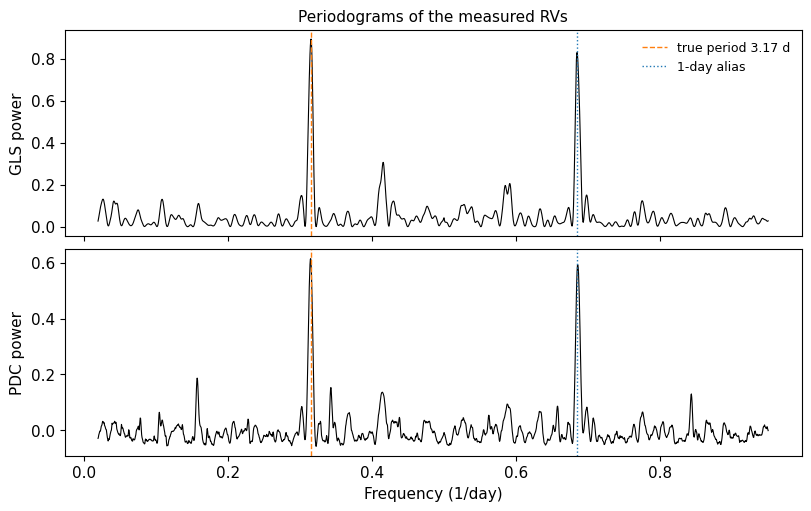

In [7]:
fig, axs = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
for ax, key in zip(axs, ("GLS", "PDC_unbiased")):
    ax.plot(pd.results_frequency[key], pd.results_power[key], "k", lw=0.8)
    ax.axvline(1 / P_true, color="tab:orange", ls="--", lw=1, label=f"true period {P_true} d")
    ax.axvline(f_alias, color="tab:blue", ls=":", lw=1, label="1-day alias")
    ax.set_ylabel(f"{key.split('_')[0]} power")
axs[0].legend(loc="upper right")
axs[0].set_title("Periodograms of the measured RVs")
axs[1].set_xlabel("Frequency (1/day)")
plt.show()

## 5. Fit the orbit

A circular orbit is a sinusoid, $v(t) = \gamma + K \sin(2\pi t/P + \phi)$. A weighted least-squares
fit (`scipy.optimize.curve_fit`, with the RV uncertainties) started at the GLS peak gives
$P$ and $K$ with their uncertainties.

In [8]:
def circular_orbit(t, P, K, phi, gamma):
    return gamma + K * np.sin(2 * np.pi * t / P + phi)

f_best = pd.results_frequency["GLS"][np.argmax(pd.results_power["GLS"])]
start = [1 / f_best, np.std(obs.vels) * np.sqrt(2), 0.0, np.mean(obs.vels)]
popt, pcov = curve_fit(circular_orbit, t, obs.vels, p0=start, sigma=obs.evels, absolute_sigma=True)
if popt[1] < 0:                                   # K < 0 is the same orbit, half a cycle later
    popt[1], popt[2] = -popt[1], popt[2] + np.pi
P_fit, K_fit = popt[0], popt[1]
P_err, K_err = np.sqrt(pcov[0, 0]), np.sqrt(pcov[1, 1])

print(f"P = {P_fit:.4f} ± {P_err:.4f} d     (truth {P_true}; off by {(P_fit - P_true) / P_err:+.1f} σ)")
print(f"K = {K_fit * 1e3:.1f} ± {K_err * 1e3:.1f} m/s     (truth {K_true * 1e3:.0f}; off by {(K_fit - K_true) / K_err:+.1f} σ)")
chi2_red = np.sum(((obs.vels - circular_orbit(t, *popt)) / obs.evels) ** 2) / (t.size - 4)
print(f"reduced chi2 of the fit: {chi2_red:.2f}")

P = 3.1705 ± 0.0032 d     (truth 3.17; off by +0.2 σ)
K = 11.5 ± 0.8 m/s     (truth 12; off by -0.6 σ)
reduced chi2 of the fit: 0.65


Both within 1σ of the truth. The reduced χ² is below 1 because these spectra have *photon* noise
(the `Simulation` default; notebook 02 used constant noise): it is lower in the line cores, where
the RV information is, so the reported uncertainties come out somewhat conservative (compare the
rms about the truth with the median uncertainty in section 3).

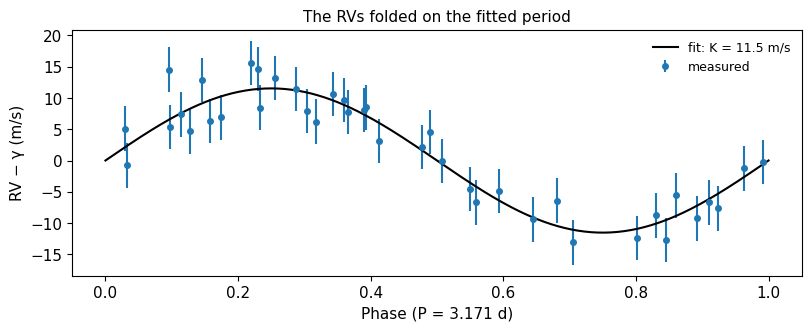

In [9]:
phase = ((t / P_fit + popt[2] / (2 * np.pi)) % 1)
grid = np.linspace(0, 1, 300)
fig, ax = plt.subplots()
ax.errorbar(phase, (obs.vels - popt[3]) * 1e3, obs.evels * 1e3, fmt="o", color="tab:blue", ms=4, label="measured")
ax.plot(grid, K_fit * 1e3 * np.sin(2 * np.pi * grid), "k", label=f"fit: K = {K_fit * 1e3:.1f} m/s")
ax.set_xlabel(f"Phase (P = {P_fit:.3f} d)")
ax.set_ylabel("RV − γ (m/s)")
ax.set_title("The RVs folded on the fitted period")
ax.legend(loc="upper right")
plt.show()

## Summary

- `Simulation` + `Observations(survey='SIMULATED', ...)` give spectra with a known truth through
  the same path as archive files.
- `calc_rv_against_template` → `init_periodicity_detector` → `calc_gls` / `calc_pdc` take you from
  spectra to a period; a sinusoid fit gives $P$ and $K$, here consistent with the truth.
- Nightly sampling makes 1-day aliases; check the alias peak before trusting a period.

Where to go next: the TODCOR deep dives in `todcor/` for the mathematics of the two-template fit,
and `docs/instruments.md` for every supported instrument.